# Final beamforming study

The latent interference line is tracked from fully observed, interference-only snapshots
\[
u_t=h_tc_t+e_t,\qquad c_t\sim\mathcal{CN}(0,\tau_t^2),\quad e_t\sim\mathcal{CN}(0,\sigma_t^2I_n).
\]
The coefficient and interference direction are never estimator inputs. The known desired steering vector enters the subsequent distortionless beamforming decision. The principal cohort adds rank-one task studies at $n=32,64$ and the declared $n=128$ feasibility condition.

For a block of $L$ snapshots generated at a common line with fixed variances, the increment is $\tau^2 WW^H/[\sigma^2(\sigma^2+\tau^2)]$, without division by $L$. Proper-complex noise has real and imaginary coordinate variances $\sigma^2/2$. Discounted/transported aggregation additionally retains every within-block weight and the recorded frame transformations.

The common $\overline P_t^+$, modal projector and $\overline P_t^{\mathrm{iso}}$ controls share the same parameter, scales, data and reporting times. The isotropic mean matches the mode and mean squared chordal distance while discarding directional differences. With uniform initialization and fixed marginal scales the mode equals EW PCA; these are not independent algorithms. GREAT is explicitly a complex extension of the real published algorithm. Loaded modal and EW covariance references have independently selected validation settings.

This notebook reads frozen, content-verified paper evidence only. Its order is theory, task performance, anisotropy, variance learning/prediction, and computation. Notebook markdown supplies explanations; the PDFs contain only panel letters, axes, legends and event markers. Every PDF page is seven inches wide with actual LaTeX text, vector text/lines and 300-dpi raster layers/previews.


In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd() if (Path.cwd()/'lib').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from scripts.make_final_notebooks import verify_figures,sha
from IPython.display import display,Image,Markdown
EXAMPLE='beamforming'
meta=verify_figures(ROOT,EXAMPLE)
assert sha(ROOT/'results'/EXAMPLE/'figure_manifest.json')=='bccef591aa0dd013b2c23405f72ed1840e3258d1f7d70337d0e130365d1724b5', 'Figures changed: regenerate this notebook'
assert sha(ROOT/'scripts/make_final_notebooks.py')=='7ab768ef230313909c005fac31b0c81ca2e7c60644e94caa9a16fcb79313961c', 'Notebook maker changed: regenerate this notebook'
FOLDER=ROOT/'results'/EXAMPLE
DISPLAYED_PREVIEWS={'results/beamforming/preview/setup.png': 'f342a0a83f9e0a612f369d5abb15272dd21de71c4232b06f5beb4bdfae6eb85e', 'results/beamforming/preview/information.png': '4698e4a0c95bcaf448e8a778500323675c66f2f0eb1e9f42f54764bd1a2c3d20', 'results/beamforming/preview/task_performance.png': '71fd0c8d291c6bb54a6ecf3b409fc5e4715a57f55ec69c13b39efce298c46543', 'results/beamforming/preview/posterior_anisotropy.png': '7b983b13b0c357bafb13f7f2ce2d843ce3cc0fbf0430ba52d576e47395360c48', 'results/beamforming/preview/noise_adaptation.png': 'b7dde8073d2b5c3ed9aba9bf363853b8c0e35e1ed9a9ed3cfbe310787494d171', 'results/beamforming/preview/predictive_calibration_page2.png': '1b7c05a60e441516240311f8576e3c4b6dbd2d5e459b4aaef638af6d9eddb193', 'results/beamforming/preview/predictive_calibration_page6.png': '9d9677bfbc4b99aa83cf73a1494c9c589e056cecddda4303289d0c86f4182364', 'results/beamforming/preview/computation_time.png': '6d783f64c74de454f2d36f4353318abac9862b7bb238da4e1dc6f4c39c50ccac'}
print('Verified',EXAMPLE,'paper evidence:',len(meta['figures']),'PDFs')

def show_saved(name,page=1):
    entry=meta['figures'][name+'.pdf']
    assert any(record['page']==page for record in entry['pages'])
    suffix='' if page==1 else '_page'+str(page)
    path=FOLDER/'preview'/(name+suffix+'.png')
    relative=path.relative_to(ROOT).as_posix()
    assert sha(path)==DISPLAYED_PREVIEWS[relative], 'Preview changed: regenerate notebook'
    display(Image(data=path.read_bytes(),width=1400))
    display(Markdown('[Vector PDF and supplementary pages](../results/'+EXAMPLE+'/'+name+'.pdf) | [Full-resolution PNG](../results/'+EXAMPLE+'/preview/'+name+suffix+'.png)'))


Verified beamforming paper evidence: 19 PDFs


## 1. Measurements and geometry

These checks distinguish the known-input and marginalized observation laws, finite-data curvature and expected information, exact aggregation and delayed actions. The sharper tracking envelope is evaluated only where its stated sufficient condition holds. Bound gaps, initialization and drift use generating quantities available for analysis, not online credible radii. Nonuniform priors, zero-signal data and concentrated inputs remain separate cohorts.

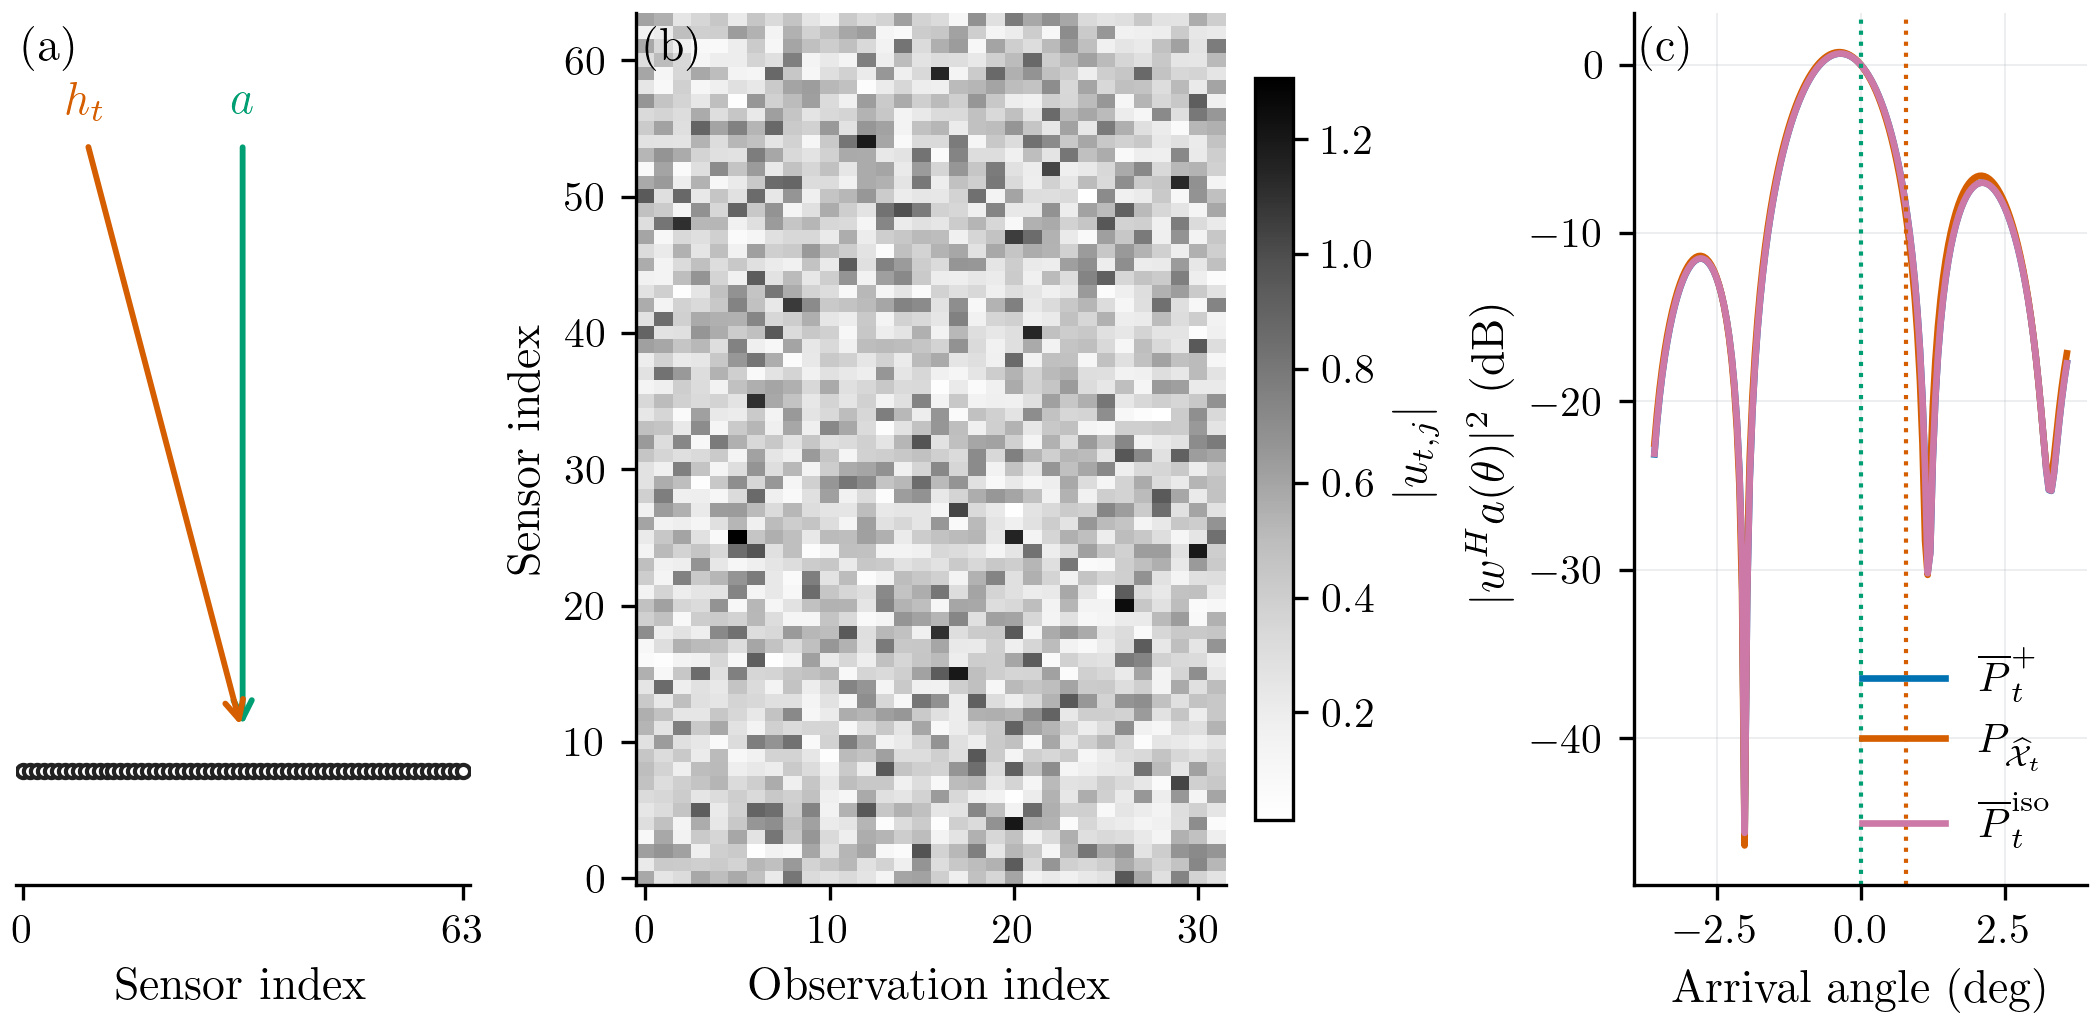

[Vector PDF and supplementary pages](../results/beamforming/setup.pdf) | [Full-resolution PNG](../results/beamforming/preview/setup.png)

In [2]:
show_saved('setup',page=1)

## 2. What the information calculation checks

The expected Fisher information describes the observation law and excitation; finite-data posterior curvature is a different object. The first panel compares analytical and empirical eigenvalues in aligned tangent coordinates. The second separates recorded-input and marginalized-input information. [Curvature](../results/beamforming/posterior_curvature.pdf), [sharp tracking bound](../results/beamforming/tracking_bound.pdf), and [block updates](../results/beamforming/block_updates.pdf) retain the locality flags, sufficient conditions, initialization/noise/drift contributions and approximation checks.

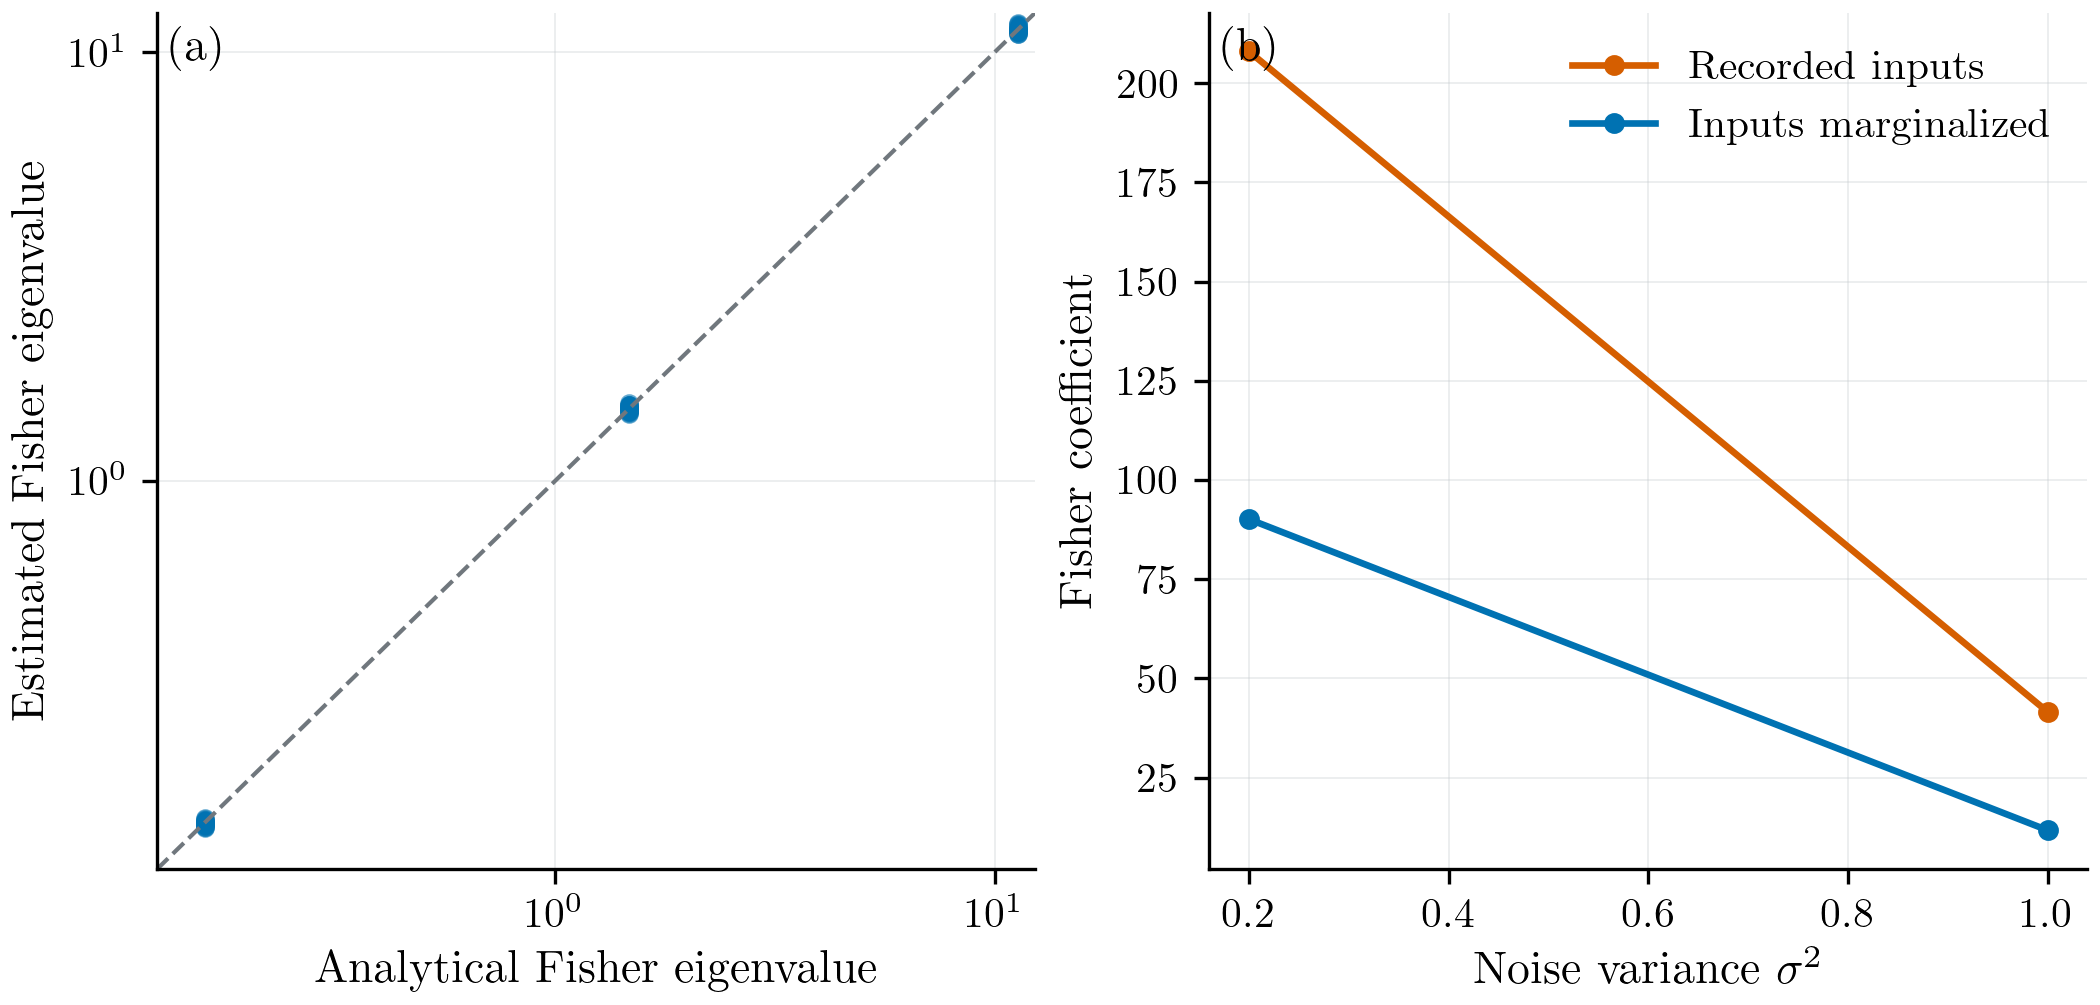

[Vector PDF and supplementary pages](../results/beamforming/information.pdf) | [Full-resolution PNG](../results/beamforming/preview/information.png)

In [3]:
show_saved('information',page=1)

## 3. Task decisions and outcomes

With $\overline P_t^+=\mathbb E[P_{\mathcal X_t}\mid u_{1:t}]$, the Bayes disturbance covariance is $\overline R_t=\sigma^2I_n+\tau^2\overline P_t^+$. For known desired steering vector $a$, the distortionless decision is
\[
w_t^{\mathrm B}=\frac{\overline R_t^{-1}a}{a^H\overline R_t^{-1}a}.
\]
The mode and matched-isotropic controls substitute their own projectors/means into the same decision.

Losses are paired on independent episodes and common held-out data. Observation/query averages within one episode are not extra repetitions. Main panels use predeclared representative conditions; the complete grids and strong controls remain in the additional comparisons and machine-readable records. A gain over GREAT may reflect input information or optimization/tracking differences; a gain attributable to posterior anisotropy requires the same-mode and matched-isotropic comparisons.

The matched isotropic mean uses the notation from the supplement:
\[
\overline P_t^{\mathrm{iso}}
=\alpha_t P_{\widehat{\mathcal X}_t}
+\xi_t(I-P_{\widehat{\mathcal X}_t}),\qquad
\alpha_t=\frac{\operatorname{tr}(P_{\widehat{\mathcal X}_t}\overline P_t^+)}{k},
\quad \xi_t=\frac{k-k\alpha_t}{n-k}.
\]
It retains the mode and mean overlap and makes the eigenvalues equal within the modal subspace and within its orthogonal complement. In beamforming this is the saved matched **mean**; no isotropic density or concentration is fitted for the plot.

The following deterministic library calls reuse the displayed episode’s stored mean; they do not rerun inference or generate observations.

In [4]:
import numpy as np
from lib.final_paper_visuals import load_evidence
from lib.final_prediction import mvdr
record=load_evidence(ROOT,EXAMPLE,'paper',components=['performance']).array('performance','stories')
M,a=record['setup_M'],record['setup_a']
R=float(record['setup_sigma2'])*np.eye(len(M))+float(record['setup_tau2'])*M
w=mvdr(R,a)
assert np.allclose(np.vdot(w,a),1.,rtol=1e-11,atol=1e-11)
assert np.allclose(R@w,np.vdot(w,R@w).real*a,rtol=1e-10,atol=1e-11)
index=list(record['setup_methods']).index('mean')
assert np.allclose(w,record['setup_weights'][index],rtol=1e-10,atol=1e-11)
print('Saved mean: distortionless action, first-order condition and saved weight agree.')


Saved mean: distortionless action, first-order condition and saved weight agree.


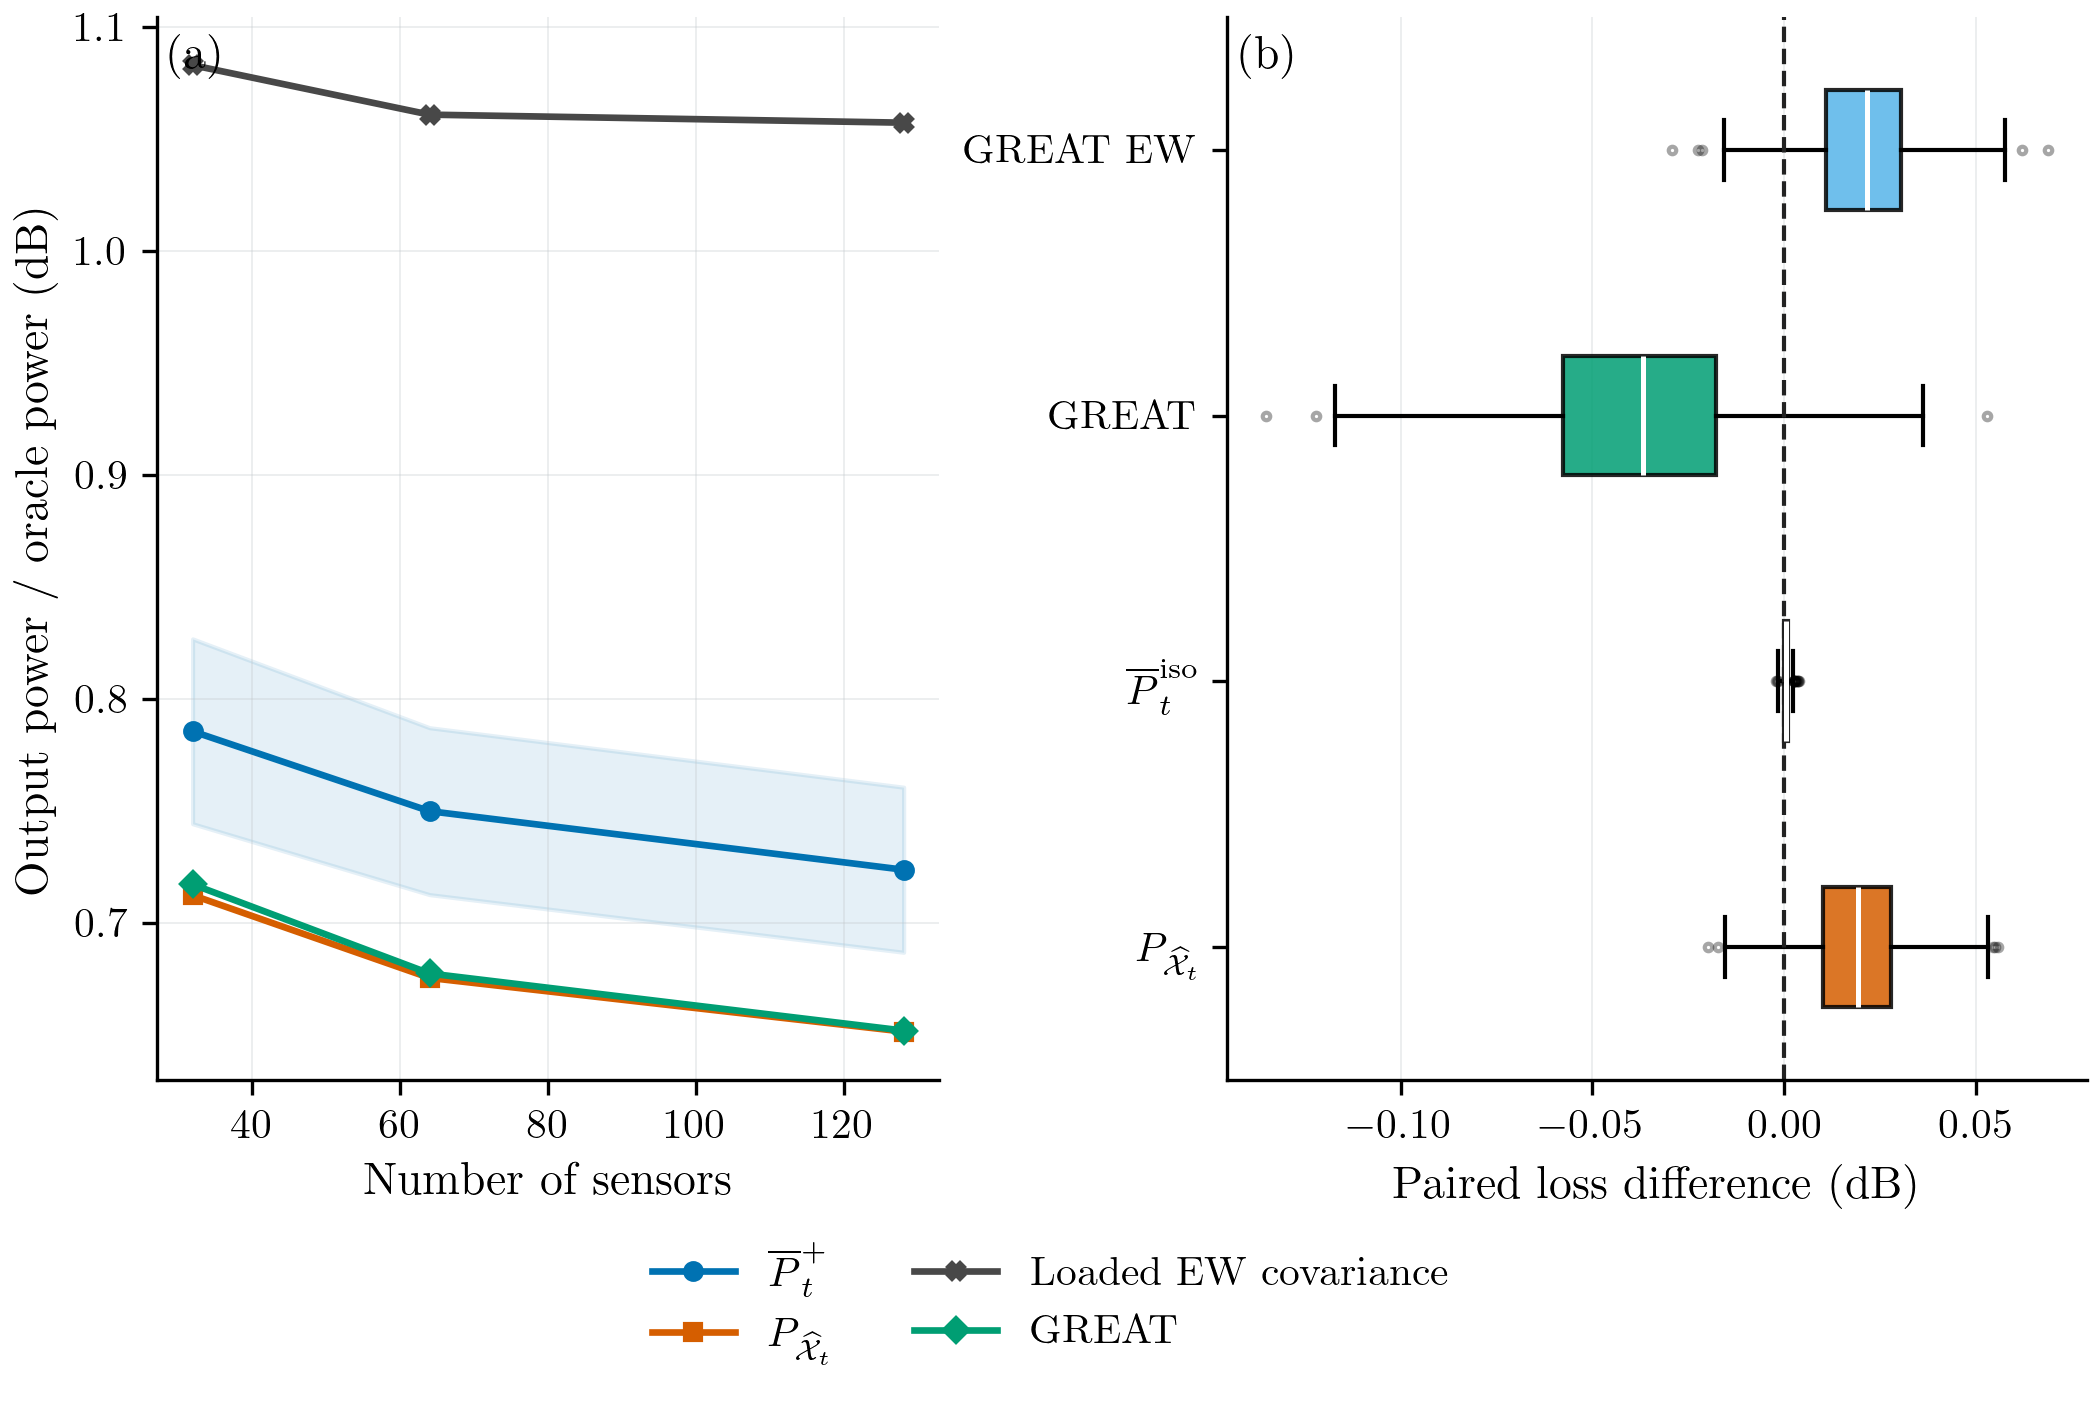

[Vector PDF and supplementary pages](../results/beamforming/task_performance.pdf) | [Full-resolution PNG](../results/beamforming/preview/task_performance.png)

In [5]:
show_saved('task_performance',page=1)

The table reports reference loss minus posterior-mean loss on the predeclared stationary $L=n$ cells at $n=32,64$. Positive values favor the posterior mean; brackets are paired pointwise 95% Student intervals in dB. Across these eight fixed comparisons, 4 intervals lie above zero, 4 lie below zero, and 0 include zero. Resolved pairs are shown relative to scheduled independent episodes. These cells are displayed together, including losses and uncertain differences; this count is descriptive and has no simultaneous-coverage guarantee.

| Condition | Reference | Paired gain [95% CI] | Resolved pairs |
| --- | --- | --- | --- |
| $n=L=32$ | $P_{\widehat{\mathcal X}_t}$ | -0.0732 [-0.0769, -0.0695] | 256/256 |
| $n=L=32$ | $\overline P_t^{\mathrm{iso}}$ | 0.00205 [0.00129, 0.00281] | 256/256 |
| $n=L=32$ | Loaded EW covariance | 0.297 [0.274, 0.321] | 256/256 |
| $n=L=32$ | GREAT | -0.0683 [-0.0733, -0.0633] | 256/256 |
| $n=L=64$ | $P_{\widehat{\mathcal X}_t}$ | -0.0745 [-0.0772, -0.0717] | 256/256 |
| $n=L=64$ | $\overline P_t^{\mathrm{iso}}$ | 0.00103 [0.000802, 0.00126] | 256/256 |
| $n=L=64$ | Loaded EW covariance | 0.311 [0.291, 0.331] | 256/256 |
| $n=L=64$ | GREAT | -0.0725 [-0.0753, -0.0697] | 256/256 |

A benefit over the mode can arise from shrinkage. A benefit over the matched isotropic control supports the value of directional posterior moments for that task and cohort. The latter comparison is the direct anisotropy test. A GREAT comparison also changes the estimator and, in contact, the available input information.

## 4. Which uncertainty matters for the decision

For a fixed query, the posterior squared response risk is
\[
\mathbb E[\|P_{\mathcal X_t}v-\overline P_t^+v\|^2\mid u_{1:t}]
=v^H[\overline P_t^+-(\overline P_t^+)^2]v.
\]
Under the full belief, using another action $\overline P_t^{\mathrm{iso}}v$ adds exactly $\|(\overline P_t^+-\overline P_t^{\mathrm{iso}})v\|^2$ to this expected response error. This is model-based optimality; paired test episodes determine whether it yields a practical advantage under the data-generating process. The matched isotropic control has the same mode and mean squared chordal distance, but can change directional risk and the task action. A fixed-radius 3D sphere encodes density by color under one shared logarithmic normalization. The continuous blue--purple--pink--yellow gradient changes only the color assigned to a density value; saved coordinates, camera, density values and angular widths are retained. Colors do not denote probability-mass quantiles. Gray curves are visible coordinate great circles that help locate directions on the sphere; they are not density contours or credible regions. Contact normals use true antipodal real-line densities. The complex-array sphere is a real-coefficient density section at the original $n=t=64$ checkpoint: it is not a physical far-field radiation pattern, a full posterior, or a normalized sphere marginal. The setup figure shows the physical array response. No estimator or benchmark parameters have changed. Mode, radius and mean overlap do not determine directional response risk. Visible anisotropy does not itself prove a repeated-experiment task advantage. PDFs retain vector LaTeX text and curves; all current preview and raster layers are 300 dpi. The font sizes, line widths and figure layout follow the implementation-notebook protocol. Inline images are scaled for reading; the full-resolution PNG and PDF links preserve the export resolution. The lower panel is a paired repeated-episode difference against the matched isotropic action. The sphere above is a real-coefficient restriction of the complex density; it has no normalized real-sphere probability interpretation.

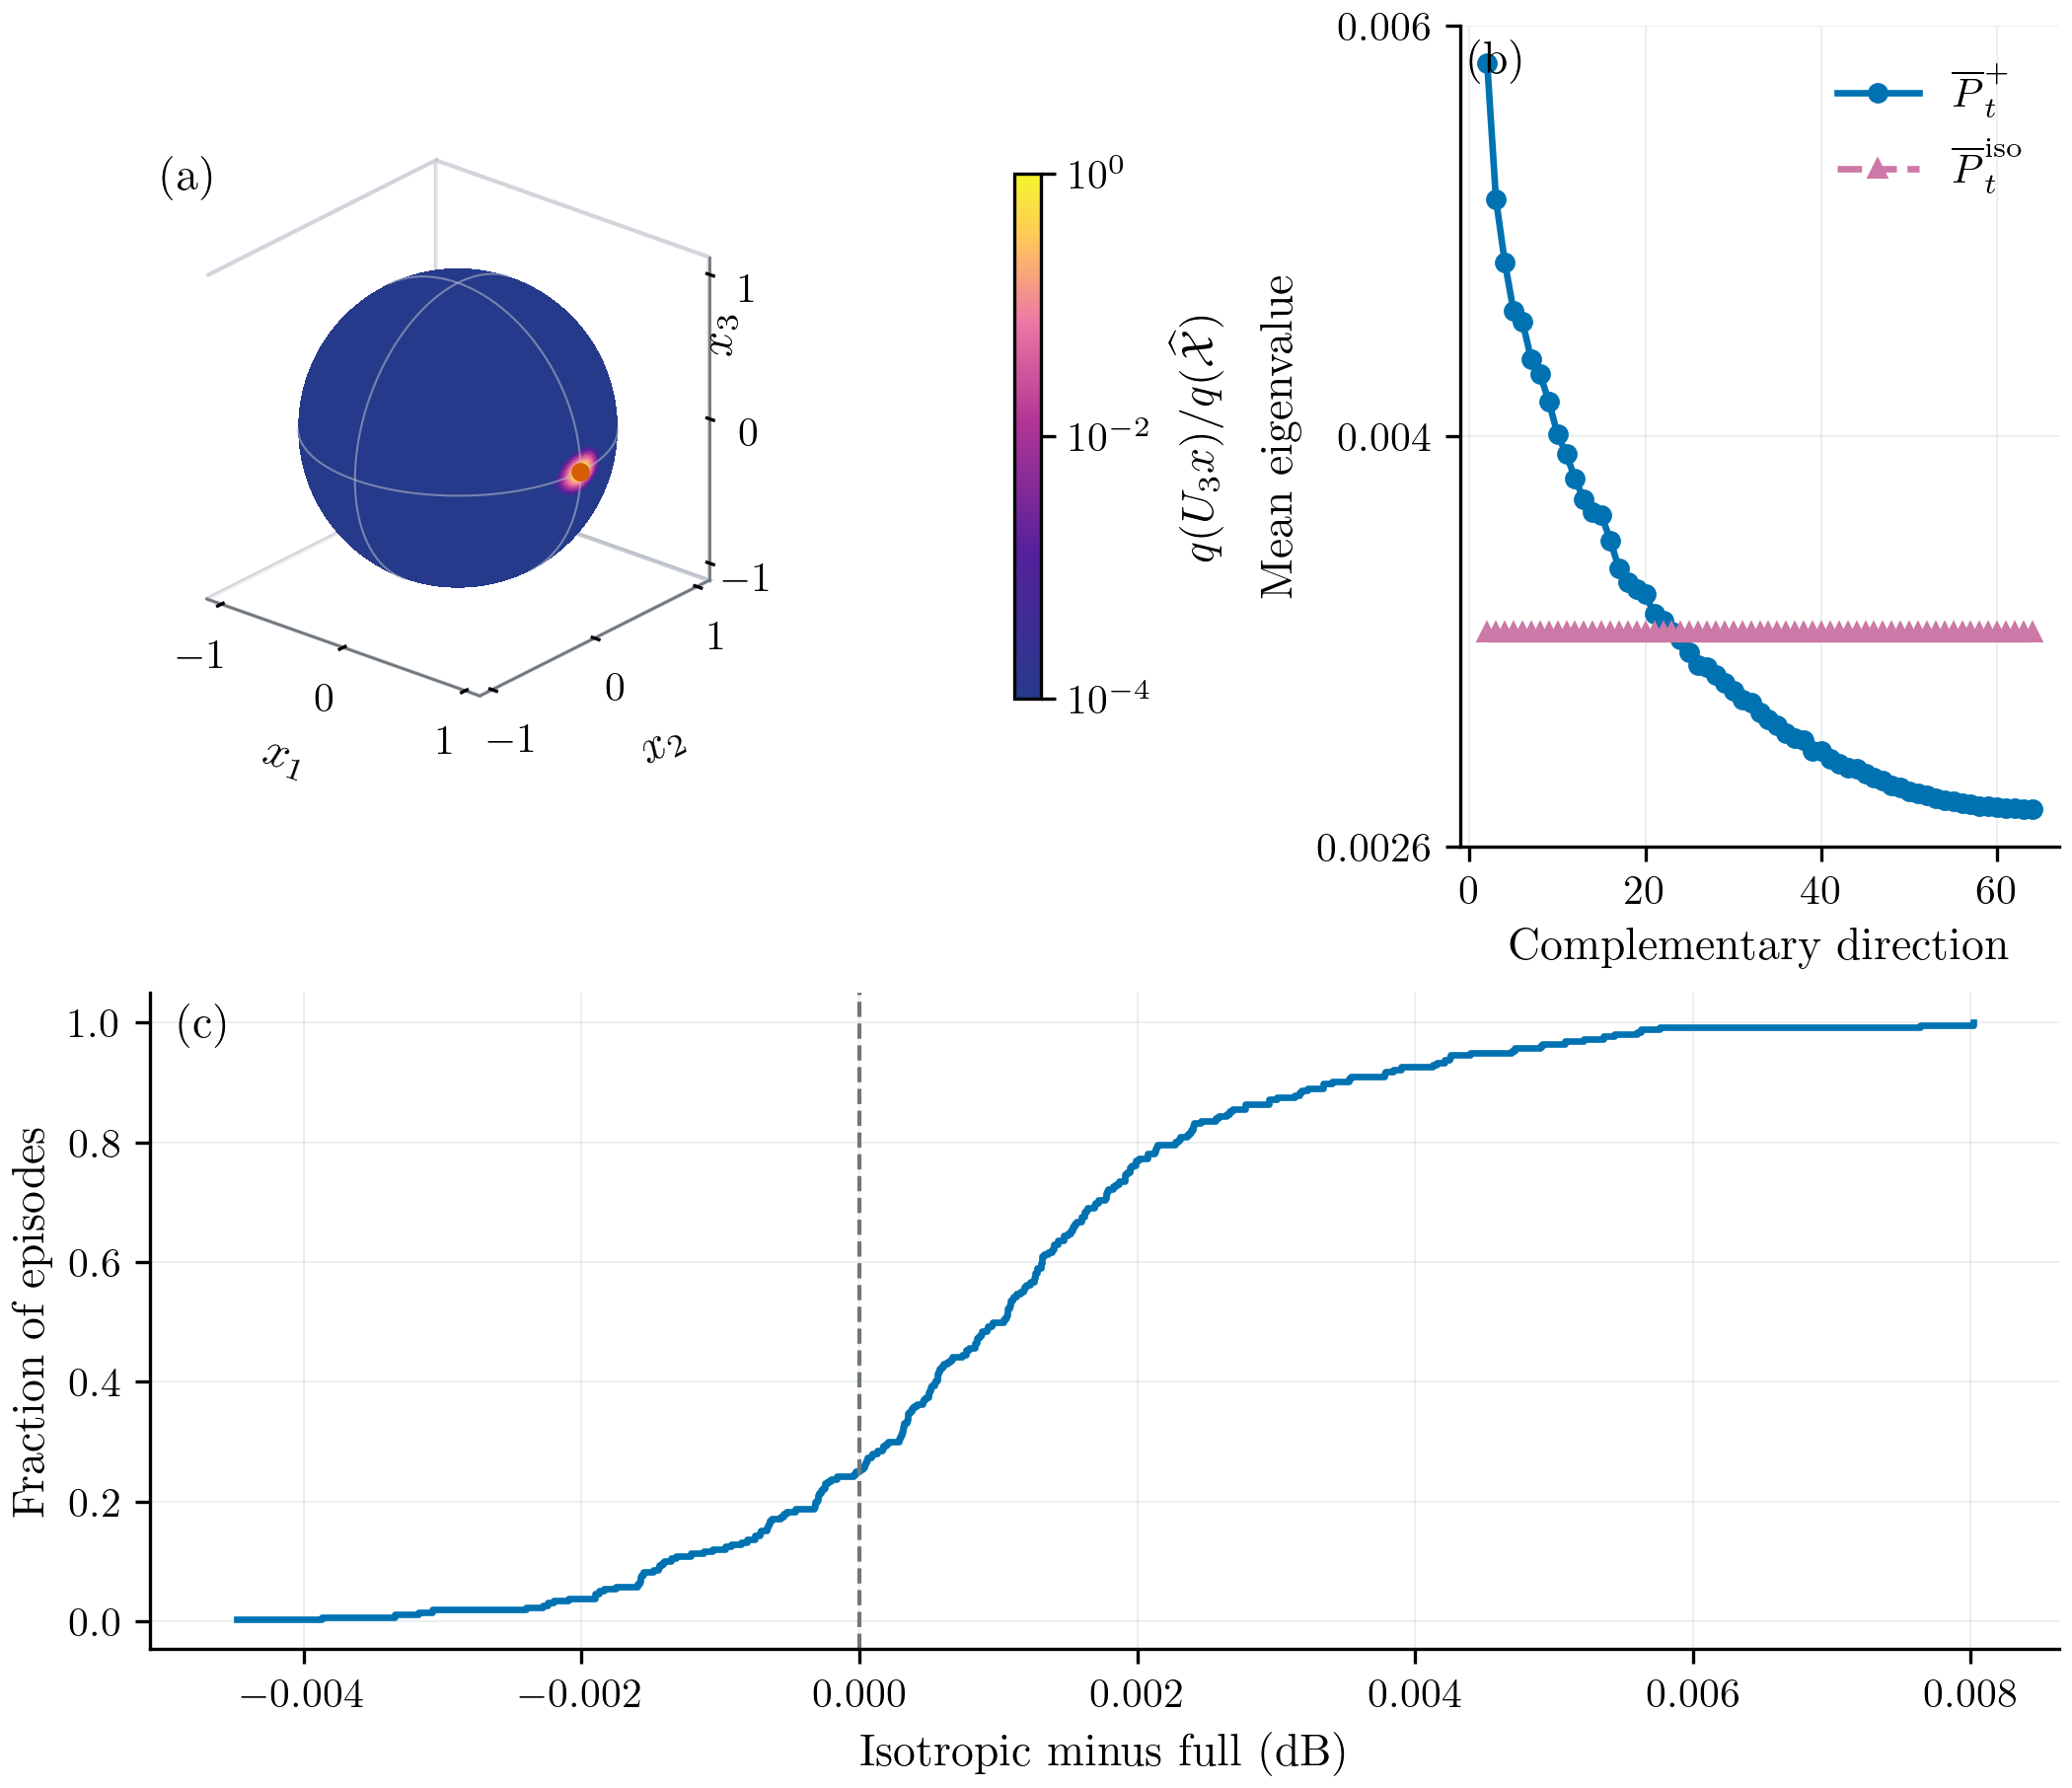

[Vector PDF and supplementary pages](../results/beamforming/posterior_anisotropy.pdf) | [Full-resolution PNG](../results/beamforming/preview/posterior_anisotropy.png)

In [6]:
show_saved('posterior_anisotropy',page=1)

## 5. Learning variances for future observations

Causal scale fits use completed disjoint past blocks and change future variances only. Each observation is assimilated once. The saved pre-observation predictive score excludes the scored observation from fitting. State, clean-response and noisy-next-observation intervals are distinct targets. Inclusion, widths and proper scores must be read together; integration/quantile precision and frequentist calibration are different checks.

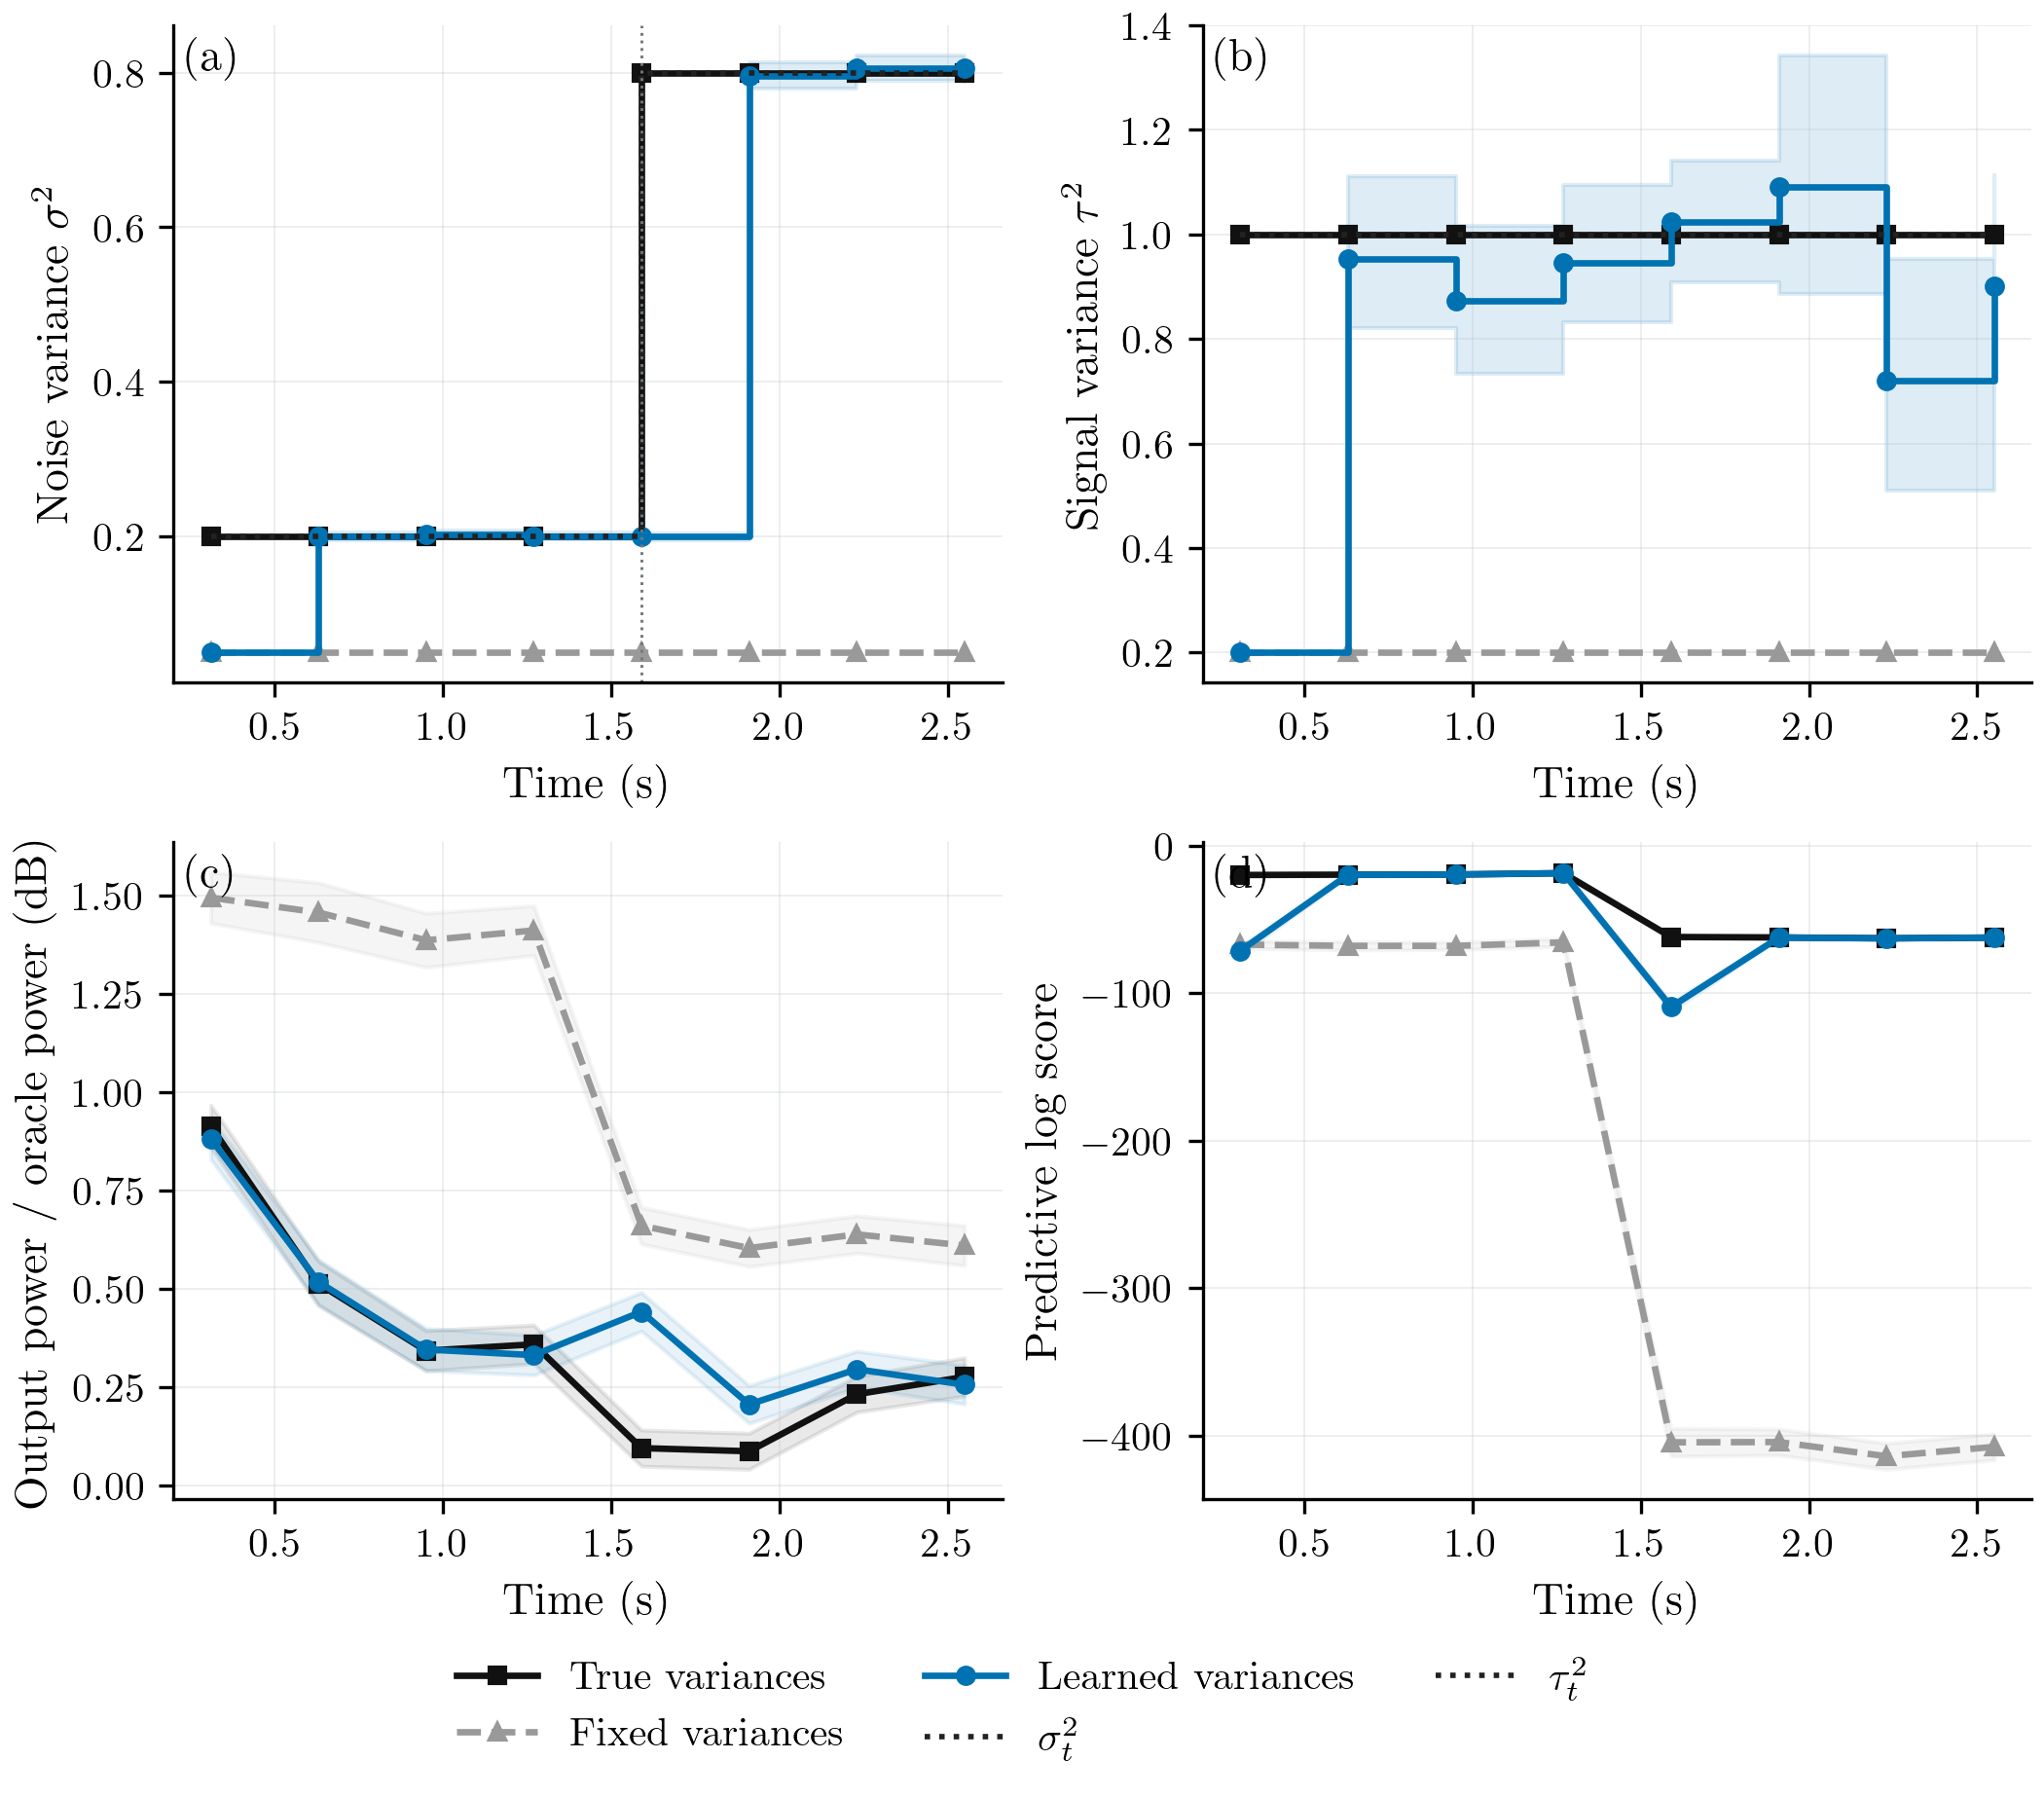

[Vector PDF and supplementary pages](../results/beamforming/noise_adaptation.pdf) | [Full-resolution PNG](../results/beamforming/preview/noise_adaptation.png)

In [7]:
show_saved('noise_adaptation',page=1)

Across all declared interventions, fixed-minus-learned observed future-task gains are noise change: 0.0929 [0.0905, 0.0953]; power change: 0.16 [0.157, 0.162]; smooth: -0.0032 [-0.00434, -0.00206]. These are paired pointwise 95% intervals over 256 independent episodes; positive gains favor learning. Beamforming values are held-out disturbance power, not decibels. Observation/query losses are averaged inside each episode. The [paired summaries](../results/beamforming/tables/paper/prediction/paired.csv) retain every control and endpoint.

A fit changes only future observations and decisions. The shaded variance trajectories show repeated-episode spread, not a posterior distribution of the variance. These displays do not establish calibration of empirical-Bayes scales.

In these fixed intervention comparisons, the intervals lie above zero for noise change, power change; the intervals lie below zero for smooth.

## 6. Inclusion is a separate test

These calibration experiments use $n=3$ reliability fixtures with unit queries. For a known unit complex query $q$, the clean scalar target is $q^H Pq$. The noisy target is $\operatorname{Re}(u_{t,1})$; contact observations are real. State ball/HPD reports target the latent subspace and remain separate from these scalar reports. The sensor counts $n=32,64,128$ belong to the task-performance cohorts; these calibration fixtures do not establish coverage at those dimensions. The first page checks the matched joint prior-predictive regime at $t=64$; the second shows the predeclared drift diagnostic at the same checkpoint. The appended PDF pages show 95% state-ball chordal radii and scalar interval widths at t=64 across all three regimes; each value is computed per independent episode. Fixed-state inclusion checks and all numerical records remain in the full PDF and summary tables.

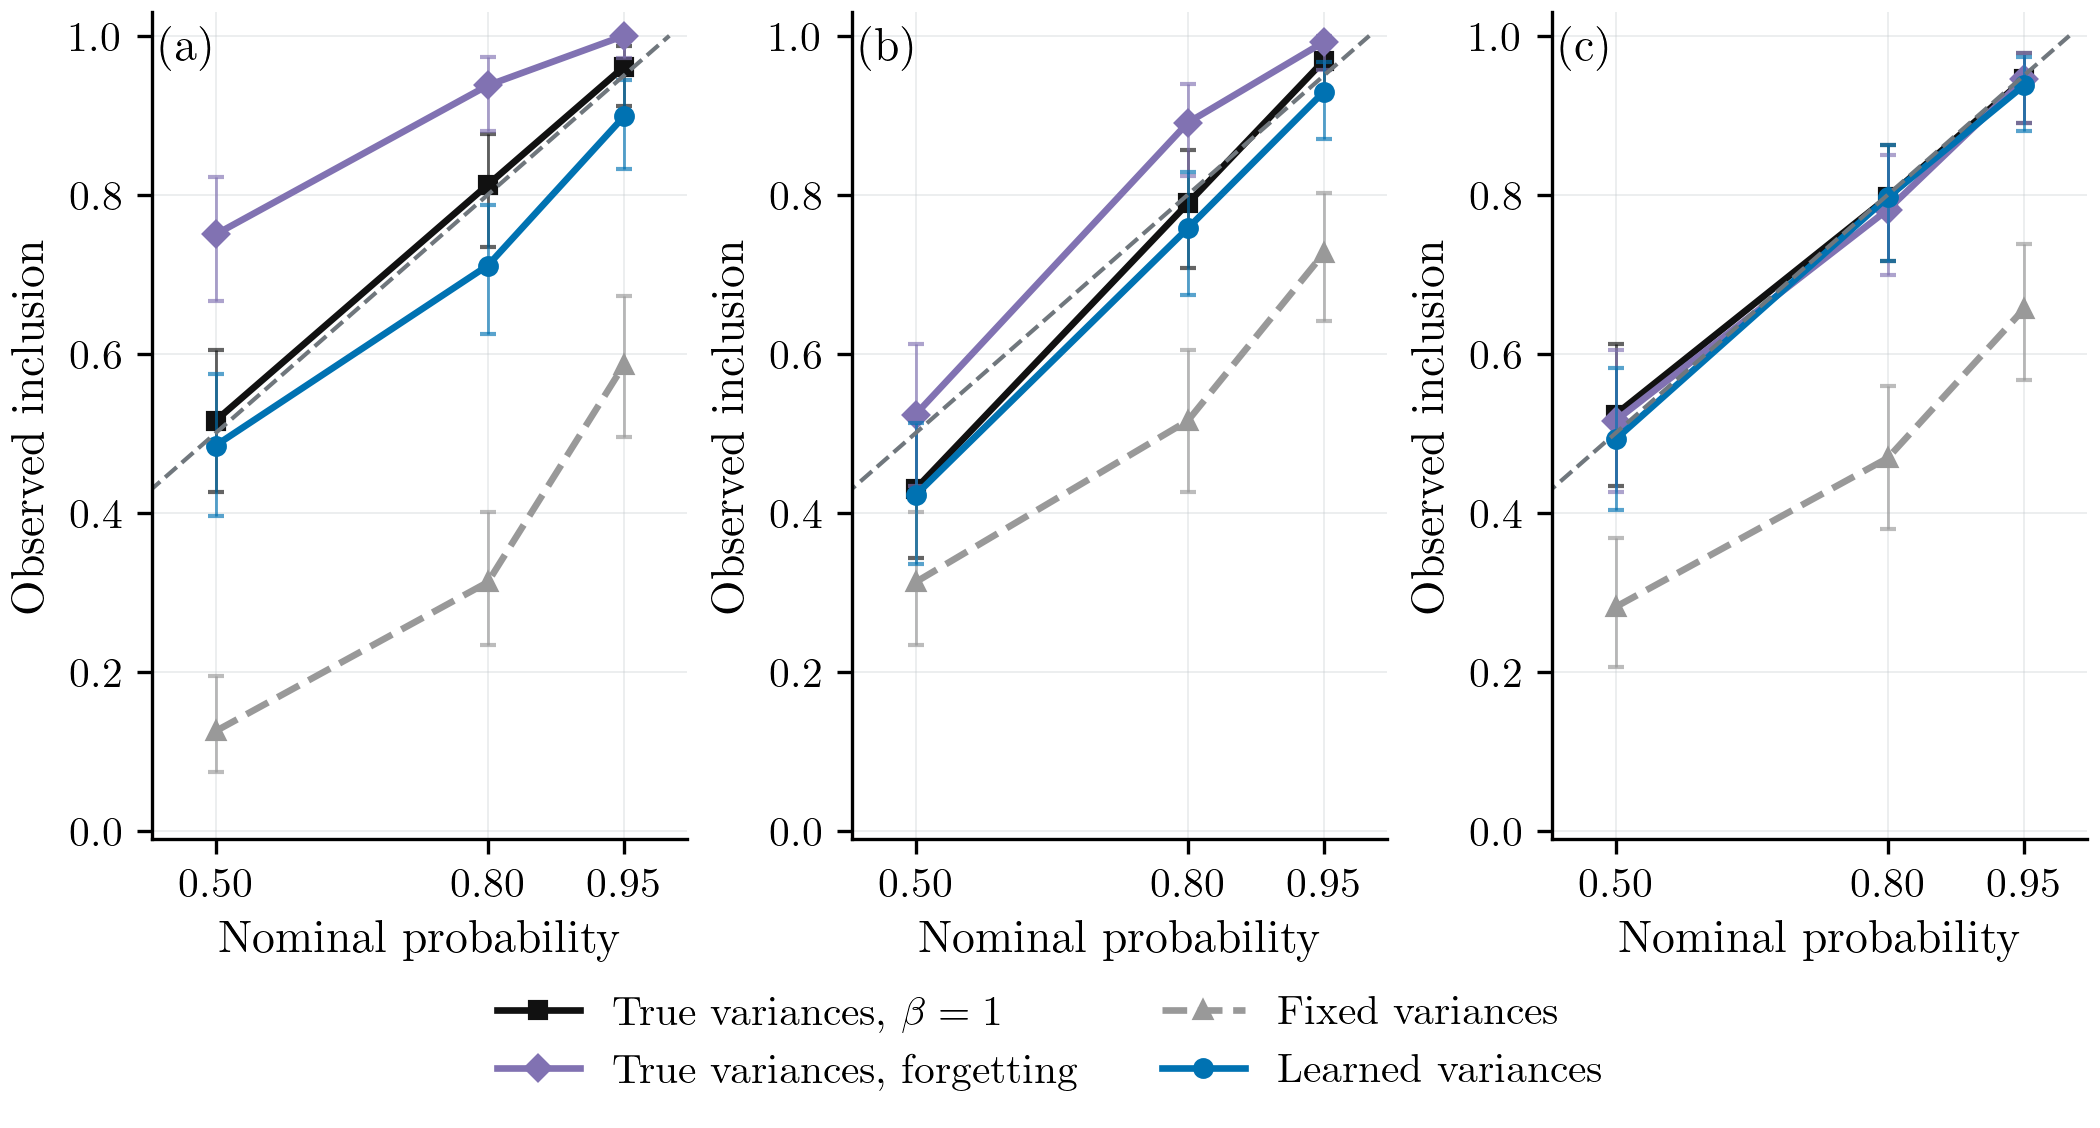

[Vector PDF and supplementary pages](../results/beamforming/predictive_calibration.pdf) | [Full-resolution PNG](../results/beamforming/preview/predictive_calibration_page2.png)

In [8]:
show_saved('predictive_calibration',page=2)

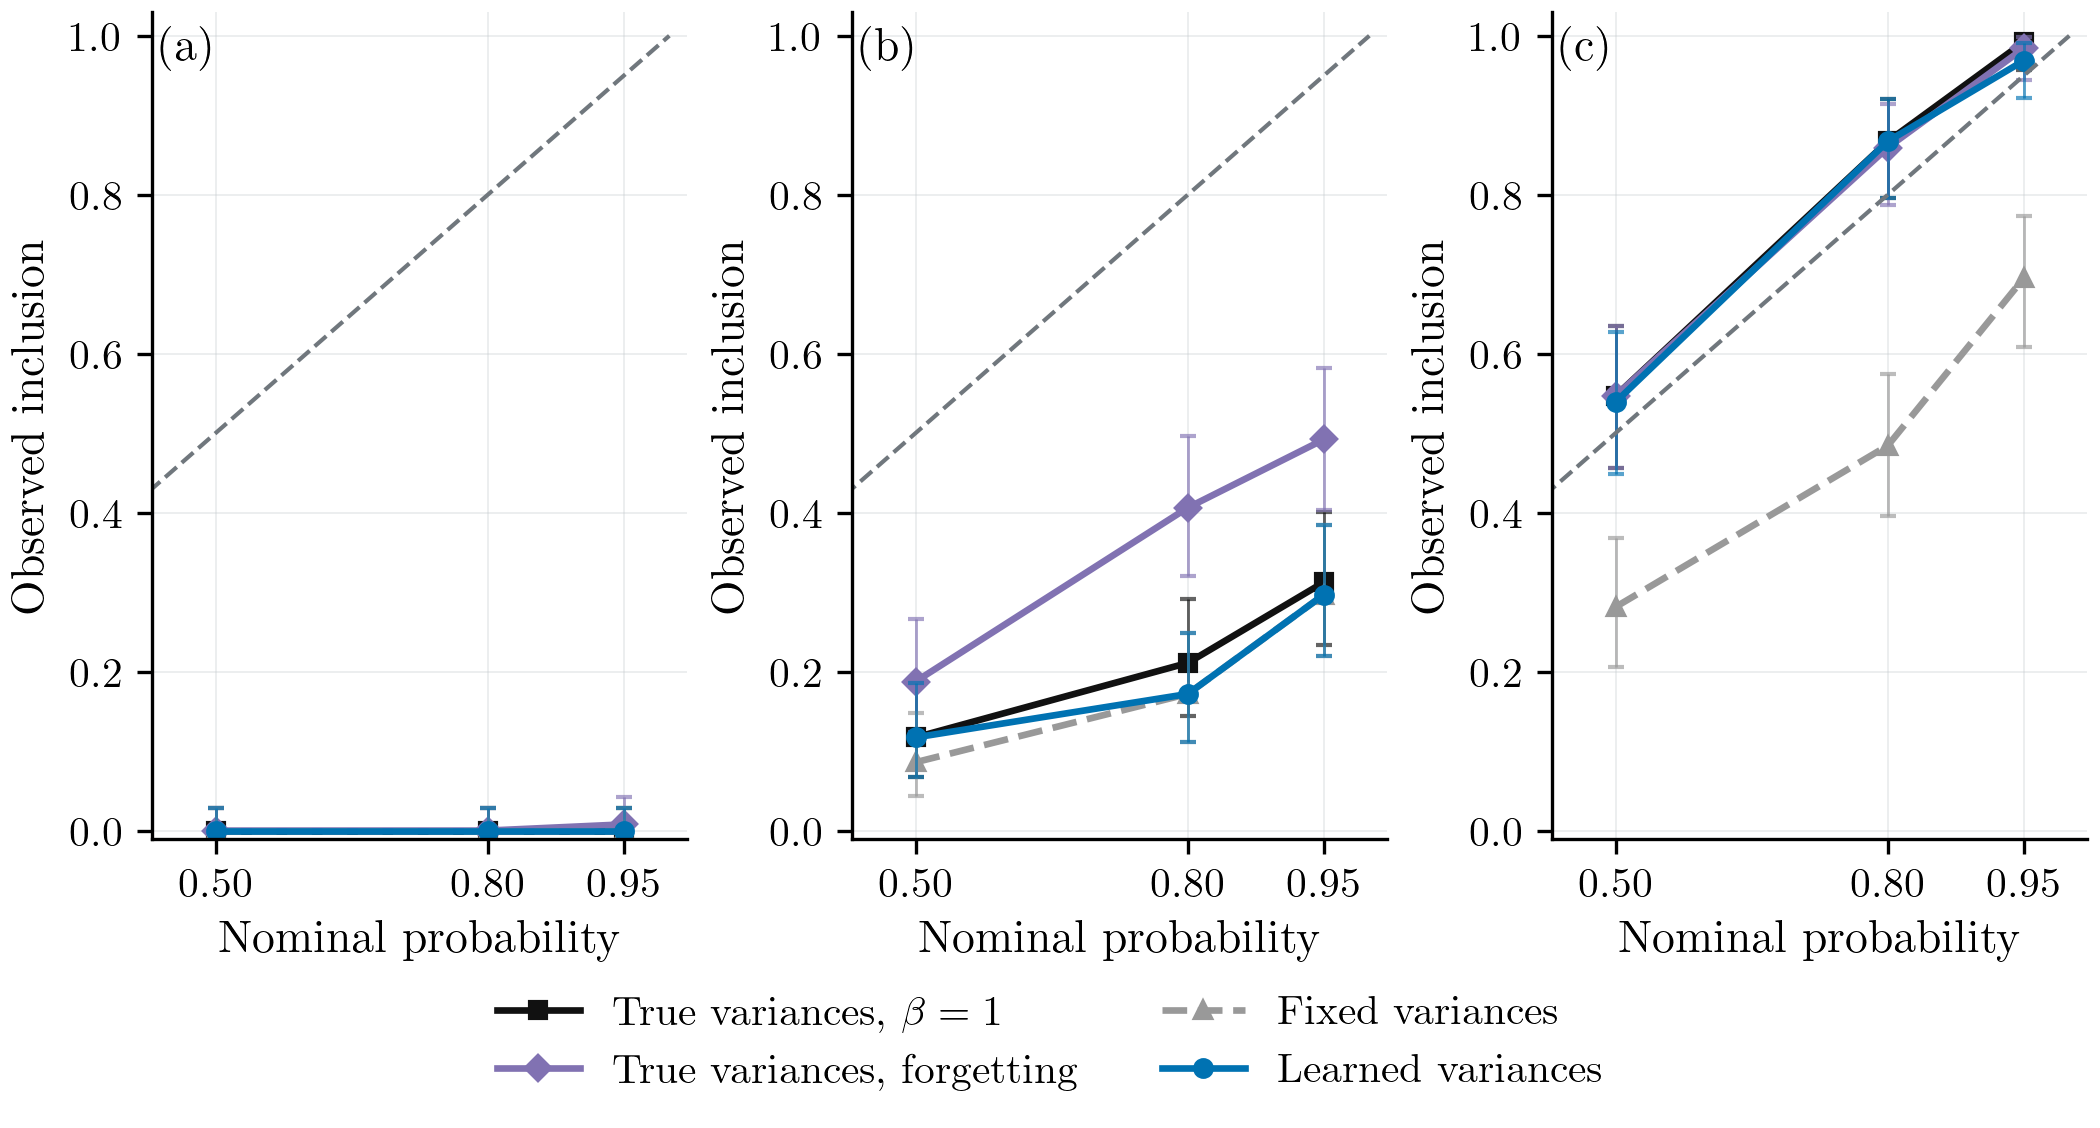

[Vector PDF and supplementary pages](../results/beamforming/predictive_calibration.pdf) | [Full-resolution PNG](../results/beamforming/preview/predictive_calibration_page6.png)

In [9]:
show_saved('predictive_calibration',page=6)

For the matched joint prior-predictive test with true variances, the predeclared $t=64$ 95% reports have inclusion State HPD: 0.961 [0.911, 0.987]; $q^H Pq$: 0.969 [0.922, 0.991]; $\operatorname{Re}(u_{t,1})$: 0.945 [0.891, 0.978]. The corresponding learned-variance reports under drift have inclusion State HPD: 0 [0, 0.0284]; $q^H Pq$: 0.297 [0.219, 0.384]; $\operatorname{Re}(u_{t,1})$: 0.969 [0.922, 0.991]. Brackets are exact binomial 95% intervals over 128 independent episodes. The upper interval is below 0.95 for State HPD, $q^H Pq$, supporting undercoverage in those drifting targets. There are 0 unresolved matched reports and 0 unresolved drifting reports in these cells.

The [calibration summaries](../results/beamforming/tables/paper/prediction/calibration_summary.csv) also report widths in each target's native units. Numerical tolerance controls how accurately a report is computed; it does not establish repeated-experiment coverage under motion or an incorrect likelihood.

## 7. Computation and the decision to use the framework

The cost plots separate measurement updates, task decisions, uncertainty reports and variance fitting. Each timing on the first PDF page processes exactly 64 observations. Its upper panel includes an update for every observation and computes a task decision at the stated interval. The lower panel separates the nonoverlapping operations for the same 64 observations: optional uncertainty reports and EM fits occur every 32 observations, independently of how often a task decision is computed. Less frequent task decisions still assimilate every observation. Summed medians of individual operations need not equal the median total elapsed time. The second PDF page reports memory, with stored arrays distinguished from tracked allocations. Timings use one predeclared data set and repeated warmed single-thread executions; repetitions of the clock are not additional statistical episodes or worst-case deadlines. Native rank/codimension-one first-moment accuracy does not certify arbitrary-rank moments, floating-point error, second moments or tails.

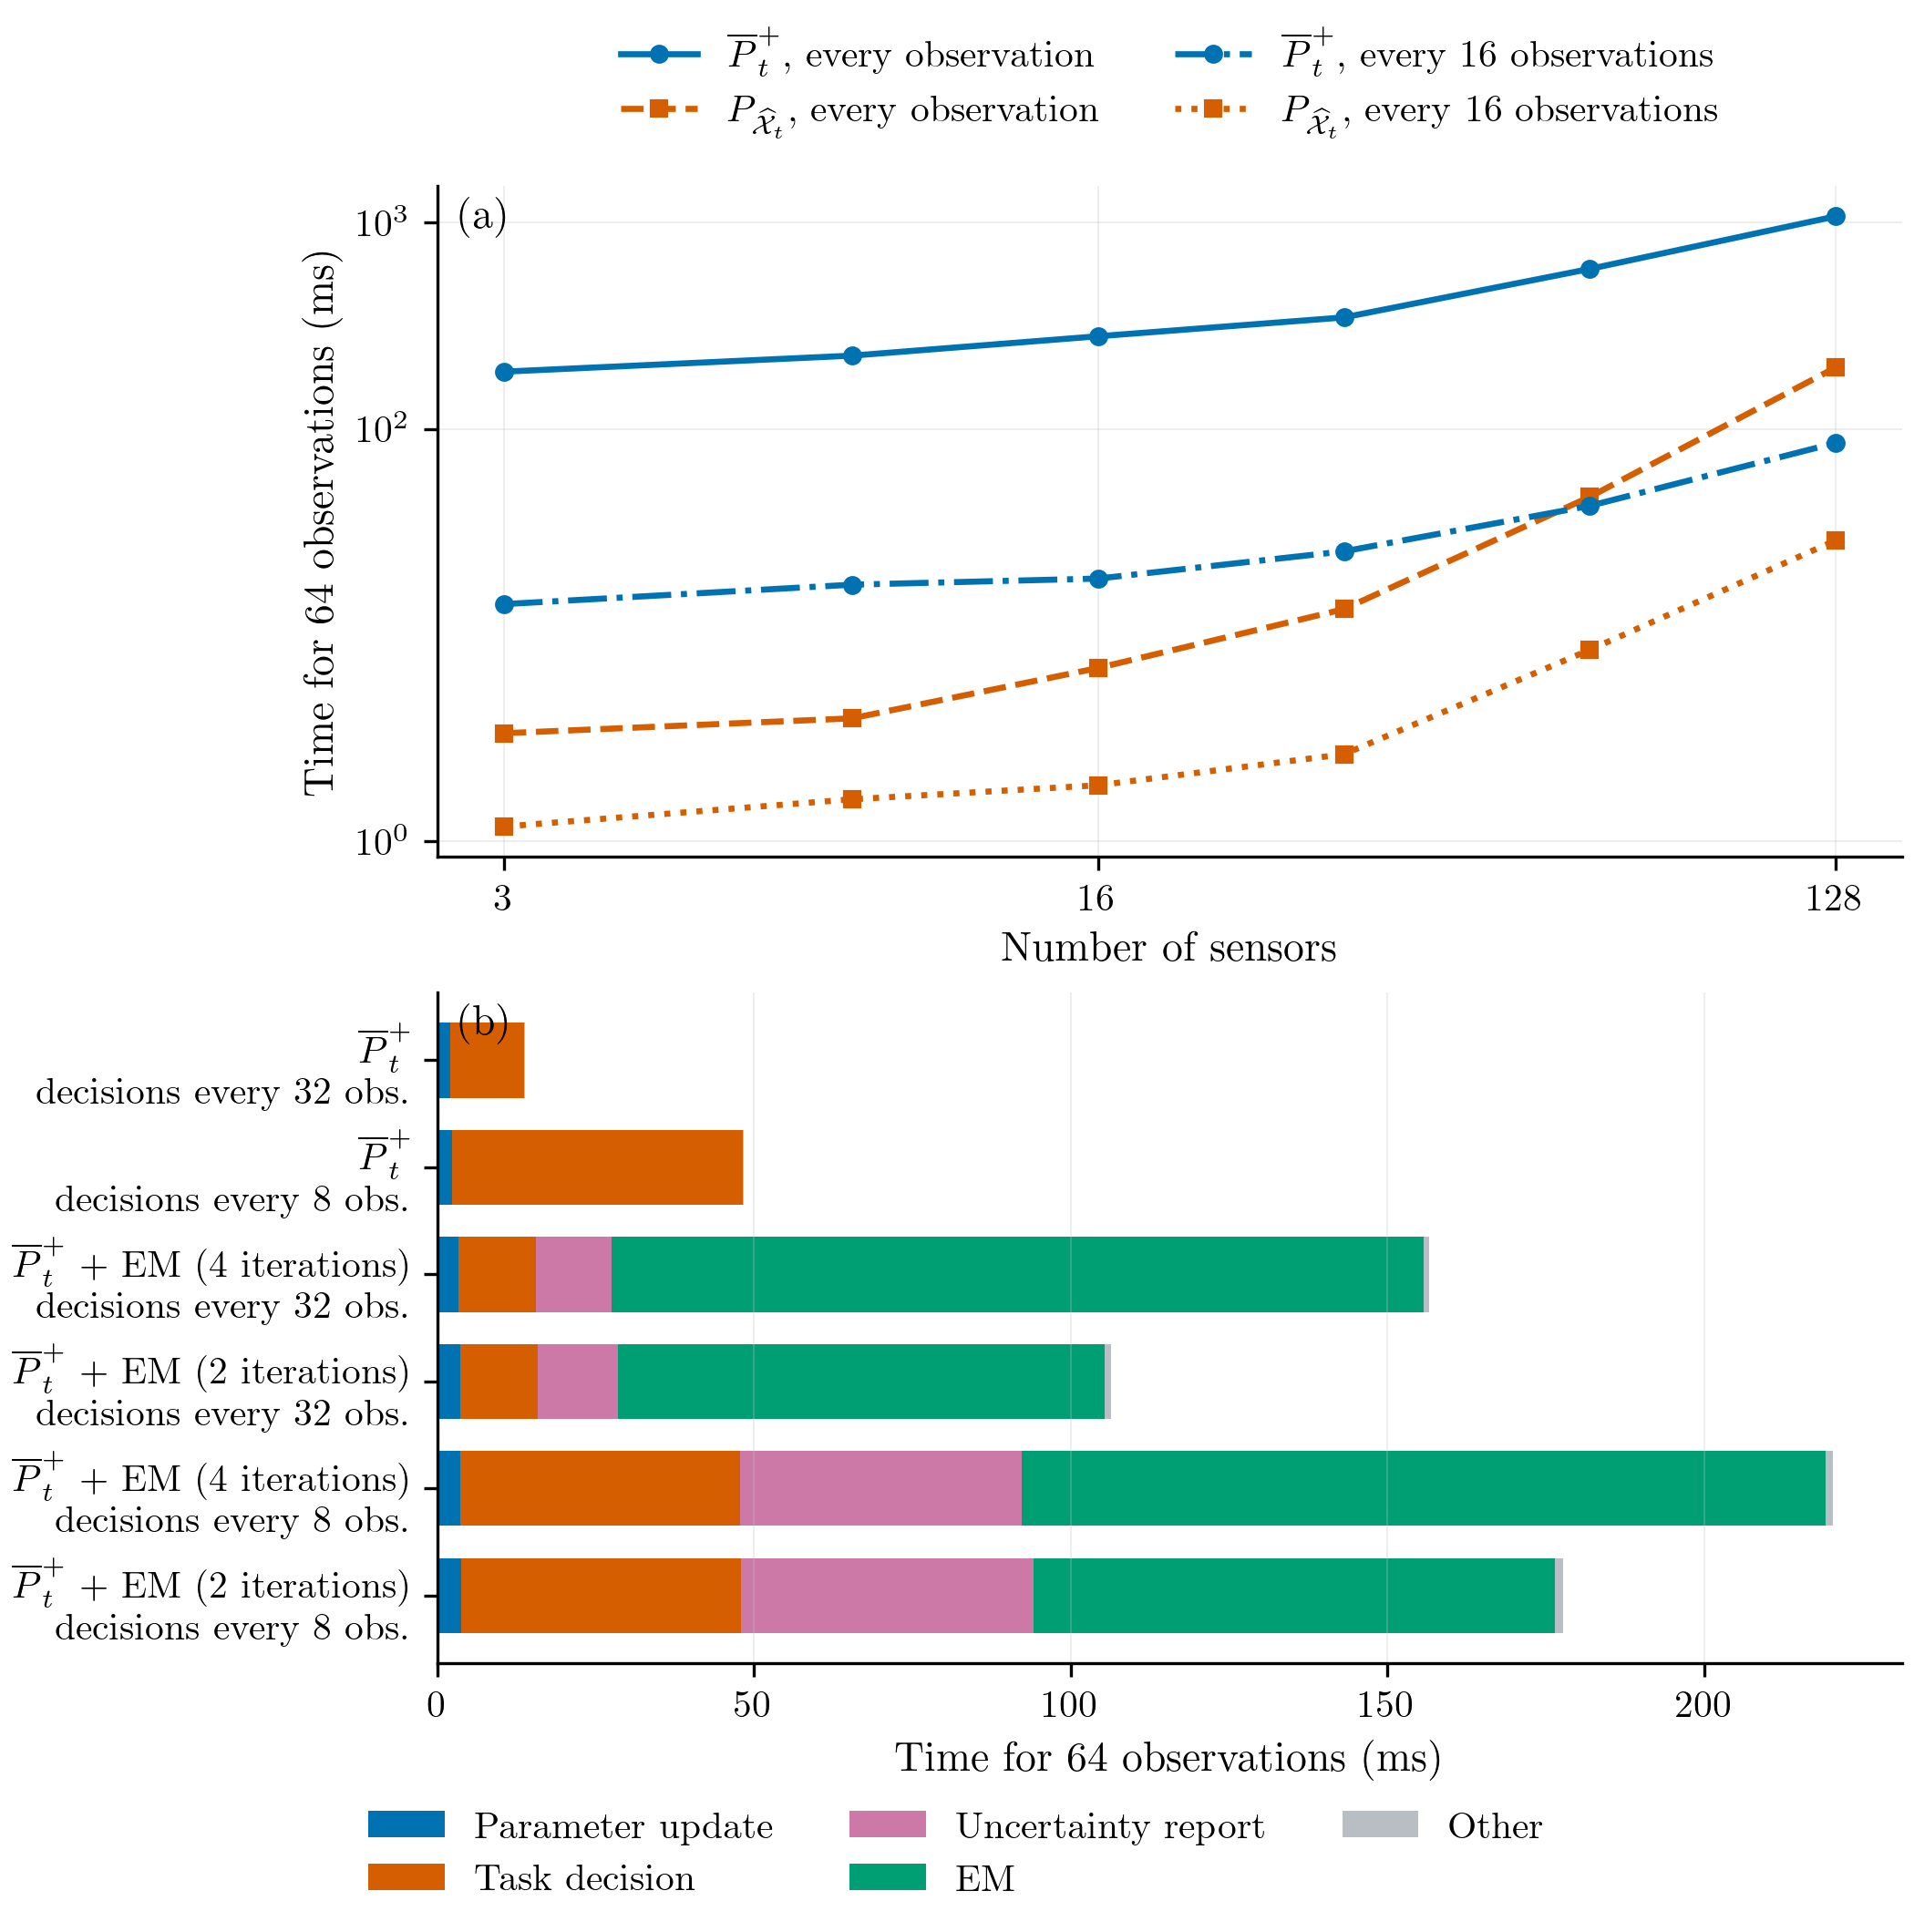

[Vector PDF and supplementary pages](../results/beamforming/computation_time.pdf) | [Full-resolution PNG](../results/beamforming/preview/computation_time.png)

In [10]:
show_saved('computation_time',page=1)

With task decisions every 64 observations and no uncertainty reports, the warmed single-thread times to process 64 observations are GREAT: 22.2 ms (90th percentile 26 ms); $\overline P_t^{\mathrm{iso}}$: 21.6 ms (90th percentile 23.1 ms); Posterior mean: 19.9 ms (90th percentile 21.7 ms); $P_{\widehat{\mathcal X}_t}$: 4.84 ms (90th percentile 6.77 ms). Each clock processes 64 observations from the same predeclared task episode; 7 clock repetitions measure execution variability, not independent task-performance episodes. The posterior mean takes 0.894 times the GREAT time, 0.922 times the $\overline P_t^{\mathrm{iso}}$ time, 4.11 times the $P_{\widehat{\mathcal X}_t}$ time. The [cost summaries](../results/beamforming/tables/paper/computation/summary.csv) include every schedule and phase.

The framework is useful when posterior means improve a consequential decision, directional risk or predictive uncertainty reporting is required, or future variance learning is useful enough to justify its measured cost. A modal or optimized tracking rule remains a sensible choice when only a subspace point is required and that cost dominates. The present results do not support universal superiority, arbitrary-rank scalability, or automatic coverage under mismatch.

## Figure catalogue and provenance

[Main-draft PDFs](../results/main/beamforming/) and [supplementary PDFs](../results/supplementary/beamforming/) provide the manuscript page selection. The complete original catalogue is linked below. The paper summary reuses the same evidence and is linked rather than displayed a second time.

- [Setup](../results/beamforming/setup.pdf)
- [Task performance](../results/beamforming/task_performance.pdf)
- [Posterior anisotropy](../results/beamforming/posterior_anisotropy.pdf)
- [Noise adaptation](../results/beamforming/noise_adaptation.pdf)
- [Information](../results/beamforming/information.pdf)
- [Posterior curvature](../results/beamforming/posterior_curvature.pdf)
- [Tracking bound](../results/beamforming/tracking_bound.pdf)
- [Block updates](../results/beamforming/block_updates.pdf)
- [Additional comparisons](../results/beamforming/additional_comparisons.pdf)
- [Variance estimation](../results/beamforming/variance_estimation.pdf)
- [Predictive calibration](../results/beamforming/predictive_calibration.pdf)
- [Predictive scores](../results/beamforming/predictive_scores.pdf)
- [Model mismatch](../results/beamforming/model_mismatch.pdf)
- [Computation time](../results/beamforming/computation_time.pdf)
- [Numerical accuracy](../results/beamforming/numerical_accuracy.pdf)
- [Paper summary](../results/beamforming/paper_summary.pdf)
- [Supp information tracking](../results/beamforming/supp_information_tracking.pdf)
- [Supp comparisons](../results/beamforming/supp_comparisons.pdf)
- [Supp variance prediction cost](../results/beamforming/supp_variance_prediction_cost.pdf)

The [figure manifest](../results/beamforming/figure_manifest.json) and [caption notes](../results/beamforming/caption_notes.md) supply proposed captions, exact selectors, source/data/configuration hashes, seeds, episode and clock repetition counts, numerical budgets, failure status and insertion paths. Historic evidence remains under `archive/a91faab/` and its preserved result paths.